In [1]:
import random
import torch
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
### Import data from csv file
### DUT containts measured data while GoldeanSample contains reference data
dut_csv_path = "DUT.csv"
gold_csv_path = "GoldenSample.csv"
dut_df =  pd.read_csv(dut_csv_path, sep=';')
gold_df =  pd.read_csv(gold_csv_path, sep=';')
print(f"\nHead of data loaded from {dut_csv_path}:\n{dut_df.head()}")
print(f"\nHead of data loaded from {gold_csv_path}:\n{gold_df.head()}")

### Short data description from DUT and GoldenSample
#print(f"\nShort data description from {dut_csv_path}:\n{dut_df.describe()}")
#print(f"\nShort data description from {gold_csv_path}:\n{gold_df.describe()}")


Head of data loaded from DUT.csv:
         Qmax     0.7Qmax     0.4Qmax    0.2Qmax    0.1Qmax     10Qmin  \
0  396.895442  276.657869  159.083122  80.354177  40.152721  25.795024   
1  395.379839  275.546994  158.739803  80.069712  40.069561  25.700682   
2  393.348961  274.071250  157.892197  79.755033  39.880217  25.620035   
3  393.466751  273.911588  157.560504  79.572483  39.826249  25.528943   
4  392.538440  273.737807  157.357378  79.381049  39.697033  25.405848   

       5Qmin     3Qmin      Qmin  
0  12.933225  7.749454  2.592394  
1  12.875334  7.721486  2.593673  
2  12.849620  7.696530  2.573100  
3  12.808280  7.675688  2.568985  
4  12.750878  7.663348  2.534514  

Head of data loaded from GoldenSample.csv:
         Qmax     0.7Qmax     0.4Qmax    0.2Qmax    0.1Qmax     10Qmin  \
0  403.873480  282.416235  160.892468  80.768521  40.339014  25.850172   
1  403.180310  281.567311  160.914273  80.382335  40.212069  25.767673   
2  401.288222  280.320807  159.940371  79.93

In [3]:
### Give numbers to labels. The labels are the same for both DUT and GoldenSample
### Hardcoded for now, but later it can be loaded from the csv file or parameters
d_labels = {    
    "Qmin": 0.16,
    "3Qmin": 0.48,
    "5Qmin": 0.8,
    "10Qmin": 1.6,
    "0.1Qmax": 2.50,
    "0.2Qmax": 5.00,
    "0.4Qmax": 10.00,
    "0.7Qmax": 17.50,
    "Qmax": 25.00,
}

### Check correlation between numeric columns for DUT
features = list(d_labels.keys())
#plt.figure(figsize=(9, 8))
#sns.heatmap(dut_df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
#plt.title("DUT Correlation matrix")
#plt.show()

### Check correlation between numeric columns for GoldenSample
#plt.figure(figsize=(9, 8))
#sns.heatmap(gold_df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
#plt.title("GoldenSample Correlation matrix")
#plt.show()


Head of delta values:
       Qmin     3Qmin     5Qmin    10Qmin   0.1Qmax   0.2Qmax   0.4Qmax  \
0 -0.016089 -0.015122 -0.034827  0.055148  0.186293  0.414344  1.809347   
1 -0.015926  0.012455  0.014053  0.066991  0.142508  0.312623  2.174470   
2 -0.015509 -0.022135 -0.062031 -0.026361  0.060799  0.175974  2.048174   
3 -0.001227  0.028362  0.031802  0.072340  0.181301  0.384270  2.365686   
4  0.024147 -0.007062 -0.002979  0.084558  0.177211  0.447107  2.533148   

    0.7Qmax      Qmax  
0  5.758366  6.978039  
1  6.020317  7.800472  
2  6.249557  7.939262  
3  6.280087  7.639654  
4  6.125520  8.020977  


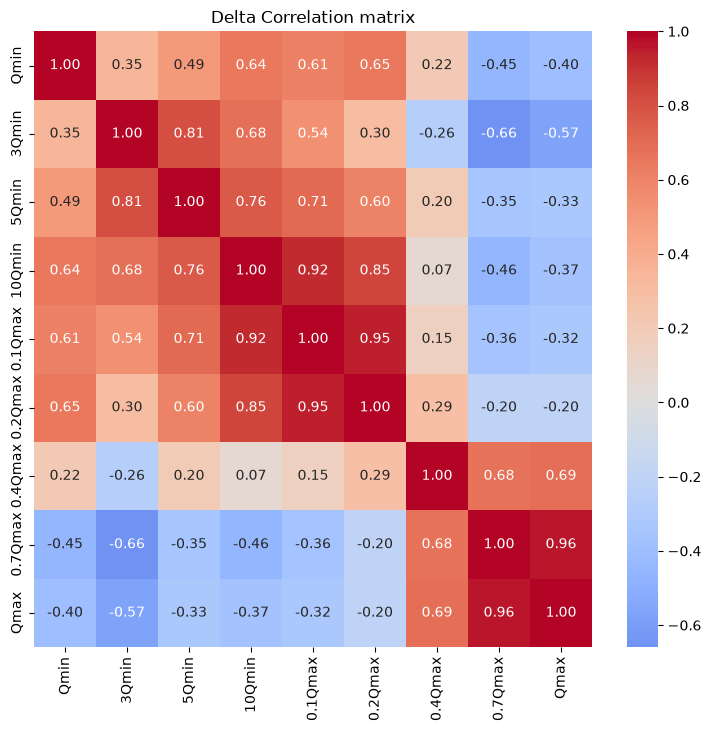

In [4]:
### Calculate delta values as (gold_df - dut_df)
### This is the correction to apply to the DUT data to match the GoldenSample data
### and the value that the model should/will try to predict
delta_df = gold_df[features] - dut_df[features]
print(f"\nHead of delta values:\n{delta_df.head()}")

### Short delta data description
#print(f"\nShort data description for delta values:\n{delta_df.describe()}")

### Check correlation between numeric columns for delta values
plt.figure(figsize=(9, 8))
sns.heatmap(delta_df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Delta Correlation matrix")
plt.show()

In [5]:
### Convert data in tensors
X = torch.tensor(list(d_labels.values()), dtype=torch.float32)  #9 elements, 1D tensor; data distribution is not uniform  
                                                                #... to check if it will be a problem for the model

y = torch.tensor([delta_df['Qmin'].iloc[0],         #How to account multiple rows?? one possbility is mean±std, 
                  delta_df['3Qmin'].iloc[0],        #maybe not a good idea, because it will be a single value,
                  delta_df['5Qmin'].iloc[0],        #and I would have a distribution of values
                  delta_df['10Qmin'].iloc[0],
                  delta_df['0.1Qmax'].iloc[0],
                  delta_df['0.2Qmax'].iloc[0],
                  delta_df['0.4Qmax'].iloc[0],
                  delta_df['0.7Qmax'].iloc[0],
                  delta_df['Qmax'].iloc[0]], dtype=torch.float32)
print(f"X: {X}, Shape: {X.shape}")
print(f"y: {y}, Shape: {y.shape}")

X: tensor([ 0.1600,  0.4800,  0.8000,  1.6000,  2.5000,  5.0000, 10.0000, 17.5000,
        25.0000]), Shape: torch.Size([9])
y: tensor([-0.0161, -0.0151, -0.0348,  0.0551,  0.1863,  0.4143,  1.8093,  5.7584,
         6.9780]), Shape: torch.Size([9])


In [6]:
### Initialize weights and bias
torch.manual_seed(191090)
w = torch.randn(1, requires_grad=True)
b = torch.tensor([random.choice(delta_df['Qmin'])], requires_grad=True)  #Qmin is closest to 0, so it is a good random starting point for the bias
print(f"w: {w}, Shape: {w.shape}")
print(f"b: {b}, Shape: {b.shape}")

w: tensor([0.0118], requires_grad=True), Shape: torch.Size([1])
b: tensor([0.0078], dtype=torch.float64, requires_grad=True), Shape: torch.Size([1])


In [7]:
### Define the forward pass
def forward(X):
    return w * X + b

### Define the loss function
def mse_loss(y_pred, y):
    return ((y_pred - y) ** 2).mean()

In [8]:
### Define parameters for the Training loop
num_epochs = 200
epochs_to_print = 20
learning_rate = 0.0001

predictions: tensor([0.0097, 0.0135, 0.0172, 0.0267, 0.0373, 0.0667, 0.1256, 0.2140, 0.3024],
       dtype=torch.float64), Shape: torch.Size([9])
y: tensor([-0.0161, -0.0151, -0.0348,  0.0551,  0.1863,  0.4143,  1.8093,  5.7584,
         6.9780]), Shape: torch.Size([9])
Initial Loss (before training): 8.698560224278776


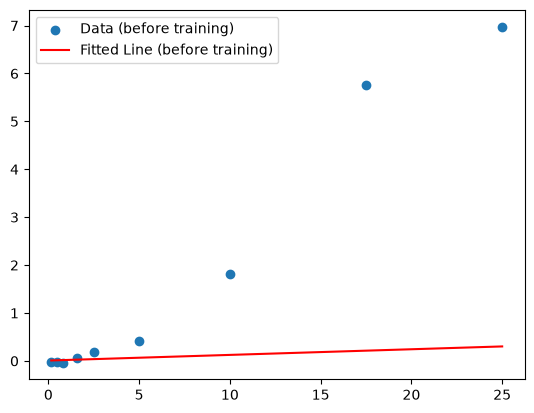

In [ ]:
### Evaluate the model before training
with torch.no_grad():
    predictions = forward(X)
    print(f"predictions: {predictions}, Shape: {predictions.shape}")
    print(f"y: {y}, Shape: {y.shape}")
    print(f"Initial Loss (before training): {mse_loss(predictions, y).item()}")

### Plot the results before training
plt.scatter(X.numpy(), y.numpy(), label='Data (before training)')
plt.plot(X.numpy(), predictions.numpy(), label='Fitted Line (before training)', color='red')
plt.legend()
plt.show()

In [10]:
### Run the training loop
for epoch in range(num_epochs):
    ### Forward pass
    predictions = forward(X)
    loss = mse_loss(predictions, y)
    
    ### Print loss every epochs_to_print epochs
    if epoch % epochs_to_print == 0:
        print(f"Epoch {epoch}: Loss = {loss.item()}")

    ### Backward pass
    loss.backward()

    ### Update parameters
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    ### Zero gradients
    w.grad.zero_()
    b.grad.zero_()

Epoch 0: Loss = 8.698560224278776
Epoch 20: Loss = 3.5495021295724194
Epoch 40: Loss = 1.5821804959520422
Epoch 60: Loss = 0.8302900668706715
Epoch 80: Loss = 0.5426973744782692
Epoch 100: Loss = 0.4324686930751307
Epoch 120: Loss = 0.389995303849332
Epoch 140: Loss = 0.3734061770633043
Epoch 160: Loss = 0.3667066113942916
Epoch 180: Loss = 0.36378640435614085


Final Loss ( post training): 0.3623118261154602


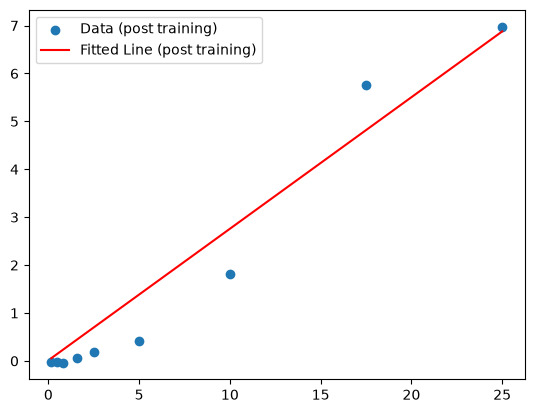

In [11]:
### Evaluate the model after training
with torch.no_grad():
    predictions = forward(X)
    print(f"Final Loss ( post training): {mse_loss(predictions, y).item()}")

### Plot the results after training
plt.scatter(X.numpy(), y.numpy(), label='Data (post training)')
plt.plot(X.numpy(), predictions.numpy(), label='Fitted Line (post training)', color='red')
plt.legend()
plt.show()